# Benchmark Plots

Reads `assets/empirical_results.csv` written by `benchmark.py`, saves the four plots used in `evaluation.md` to `assets/`, and computes the growth rates that are compared against the Complexity Analysis in `planning.md`. Run it from the `src` folder.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [2]:
# Generated files (the CSV and the plots) are stored in the assets folder next to src.
ASSETS_DIR = Path("../assets")

df = pd.read_csv(ASSETS_DIR / "empirical_results.csv")
df.head()

,Experiment,Algorithm,Rows,Columns,Cells,Trial,Time
0,Comparison,Baseline,2,2,4,1,0.000010
1,Comparison,Baseline,2,2,4,2,0.000003
2,Comparison,Baseline,2,2,4,3,0.000002
3,Comparison,Baseline,2,2,4,4,0.000001
4,Comparison,Baseline,2,2,4,5,0.000001


In [3]:
# Split the results by experiment so the two size ranges are not mixed.
comparison = df[df["Experiment"] == "Comparison"]
scalability = df[df["Experiment"] == "Scalability"]

# Use the same color for each algorithm in every plot.
algorithms = ["Baseline", "DP"]
palette = dict(zip(algorithms, sns.color_palette(n_colors=len(algorithms))))


def plot_times(data, x, xlabel, ylabel, xscale="linear", yscale="linear"):
    """Plot the median time of each algorithm against x on the given axis scales."""
    plt.figure(figsize=(4, 3))
    ax = sns.lineplot(data=data, x=x, y="Time", hue="Algorithm", palette=palette,
                      estimator="median", errorbar=None, marker="o")
    sns.move_legend(ax, "lower center", bbox_to_anchor=(0.5, 1), ncol=2,
                    title=None, frameon=False, fontsize=8)
    ax.set_xscale(xscale)
    ax.set_yscale(yscale)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax


def save_and_show(filename):
    """Save the current plot to the assets folder and display it."""
    plt.tight_layout()
    plt.savefig(ASSETS_DIR / filename, dpi=200)
    plt.show()

In [4]:
# Median time in seconds over the 5 trials (the values plotted below), and how many
# times faster the DP is wherever both algorithms ran on the same chart.
summary = df.pivot_table(index=["Experiment", "Rows", "Cells"], columns="Algorithm",
                         values="Time", aggfunc="median")[algorithms]
summary["Speedup"] = summary["Baseline"] / summary["DP"]
summary.round({"Baseline": 6, "DP": 6, "Speedup": 1})

Algorithm                 Baseline        DP  Speedup
Experiment  Rows Cells                               
Comparison  2    4        0.000002  0.000002      1.0
            3    9        0.000008  0.000002      3.3
            4    16       0.000029  0.000004      7.5
            5    25       0.000106  0.000005     20.9
            6    36       0.000426  0.000007     59.8
            7    49       0.001618  0.000011    152.9
            8    64       0.006006  0.000014    422.7
            9    81       0.020936  0.000018   1149.8
            10   100      0.074561  0.000022   3357.4
            11   121      0.261877  0.000027   9866.5
            12   144      0.911303  0.000032  28777.7
            13   169      3.095239  0.000037  84128.0
Scalability 100  10000         NaN  0.002315      NaN
            250  62500         NaN  0.014629      NaN
            500  250000        NaN  0.059464      NaN
            1000 1000000       NaN  0.242857      NaN
            1500 2250000       NaN  0.579589      NaN
            2000 4000000       NaN  1.084977      NaN

## Experiment 1: Comparison

Both algorithms on n x n charts with n = 2 to 13.

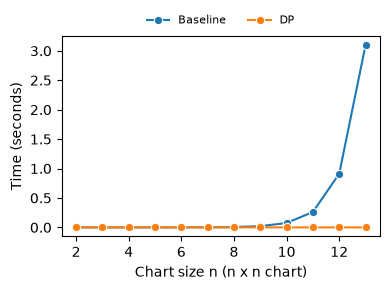

In [5]:
ax = plot_times(comparison, "Rows", "Chart size n (n x n chart)", "Time (seconds)")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_and_show("comparison_plot.png")

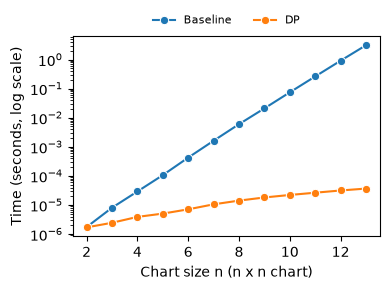

In [6]:
# On a logarithmic time axis, exponential growth appears as a straight line.
ax = plot_times(comparison, "Rows", "Chart size n (n x n chart)",
                "Time (seconds, log scale)", yscale="log")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
save_and_show("comparison_plot_log.png")

## Experiment 2: Scalability

Only the DP, on n x n charts with n = 100 to 2,000 (10,000 to 4,000,000 coordinates).

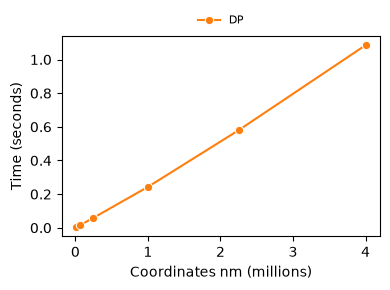

In [7]:
# Both axes are linear, so a running time proportional to nm appears as a straight line.
ax = plot_times(scalability, "Cells", "Coordinates nm (millions)", "Time (seconds)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1e6:g}"))
save_and_show("scalability_plot.png")

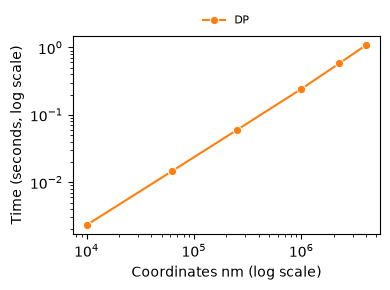

In [8]:
plot_times(scalability, "Cells", "Coordinates nm (log scale)", "Time (seconds, log scale)",
           xscale="log", yscale="log")
save_and_show("scalability_plot_log.png")

## Growth Rates

The numbers below are compared against the Complexity Analysis in `planning.md`.

In [9]:
# On a log-log plot a running time of the form c * (nm)^k is a straight line of slope k,
# so a fitted slope close to 1 matches the Theta(nm) bound for the DP.
dp_medians = scalability.groupby("Cells")["Time"].median()
slope, intercept = np.polyfit(np.log(dp_medians.index), np.log(dp_medians.values), 1)
print(f"DP log-log slope: {slope:.3f}")

DP log-log slope: 1.024


In [10]:
# The baseline bound O(nm * 3^(n-1)) with m = n predicts that going from an n x n chart
# to an (n+1) x (n+1) chart multiplies the time by at most 3 * ((n+1)/n)^2: one more row
# triples the number of paths in the worst case, and the nm factor grows as well.
baseline_medians = comparison[comparison["Algorithm"] == "Baseline"].groupby("Rows")["Time"].median()
growth = pd.DataFrame({
    "From n": baseline_medians.index[:-1],
    "To n": baseline_medians.index[1:],
    "Measured ratio": baseline_medians.values[1:] / baseline_medians.values[:-1],
})
growth["Upper-bound ratio"] = 3 * (growth["To n"] / growth["From n"]) ** 2
growth.round(2)

,From n,To n,Measured ratio,Upper-bound ratio
0,2,3,4.62,6.75
1,3,4,3.62,5.33
2,4,5,3.64,4.69
3,5,6,4.00,4.32
4,6,7,3.80,4.08
5,7,8,3.71,3.92
6,8,9,3.49,3.80
7,9,10,3.56,3.70
8,10,11,3.51,3.63
9,11,12,3.48,3.57
